# Aligning the NEOARM by recipe

This notebook walks the alignment guide (`design/alignment_guide.md`) from top to bottom on the
simulated NEOARM. Each step of the guide is a section. The section quotes the guide and shows
what the step looks at. Then it runs the step's script, shows the same view again and checks
the step's end point. A step without a script says so, and why.

The scripts are the files that run at the microscope (`centre_aperture.py`, `tilt_balance.py`,
`shift_balance.py`, `ht_centre.py`). The notebook runs them unchanged. They run one after
another on one simulated microscope, which the notebook installs at the top. So each script
starts where the last one left the microscope. No script needs a model of the microscope. Each
measures frames and nulls what the guide asks it to null (requirement S8).

The simulated NEOARM starts with the console's settings of MAG X40k and spot 2. This is the
state after the guide's first step, "Load existing alignments", with a recent alignment that is
nearly right. Its pivot points are a few hundred balance units off. TiltBal is off by
(600, -400) and ShiftBal by (-300, 200), hidden numbers. In this simulated column a kick near
the coils reaches the specimen almost as a pure tilt, so these errors barely show. Its
condenser aperture is off centre, and the beam's HT centre is out.

At some steps an operator acts at the console, for example to select an aperture or to put the
specimen in. jemwrap does not let a script do these, so the notebook does them and says so.

In [1]:
import os

# A rehearsal on the simulated NEOARM runs on the CPU.
os.environ.setdefault("JAX_PLATFORMS", "cpu")

import runpy  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402

from simulated_neoarm import CROSS_GRATING, install_simulated_neoarm  # noqa: E402

# The one simulated NEOARM of this notebook. Every script finds it installed and uses it.
scope = install_simulated_neoarm()
# The balances at the start, to see later how far the scripts moved them.
scope_start = {name: list(scope.deflectors[name]) for name in ("TiltBal", "ShifBal")}

from PyJEM import TEM3, detector, sightx  # noqa: E402

from jemwrap import MicroscopeMonitor, PyJEMAdapter  # noqa: E402
from jemwrap.control import (  # noqa: E402
    read_value,
    restore,
    set_value,
    settable_snapshot,
    take_frame,
)
from microscope_functions import (  # noqa: E402
    APPROACH_DAC,
    enter_mode,
    feature_shift,
    find_beam,
    leave_mode,
    set_lens_from_below,
)

The notebook takes its own frames through a jemwrap monitor, as the scripts do with theirs.

In [2]:
# The notebook's own monitor, for its views. The scripts make their own.
monitor = MicroscopeMonitor(
    adapter=PyJEMAdapter(
        connect=False, tem3_module=TEM3, detector_module=detector, sightx_module=sightx
    ),
    rate_hz=1000.0,
)
MAG, DIFF = 0, 4

## The views

Each view takes two SightX frames that differ in the one thing that the step looks at. That is
CL3 below and above the crossover, or the two sides of a wobbler. The view shows the first frame
in red and the second in cyan. Where they agree, the picture is white. Then the view sets every
value it changed back, the lenses from below.

In [3]:
def two_frames(mode, row, first, second, cl3_step=0, ht_wobbler=False):
    """Return two frames at function mode ``mode`` and row ``row``.

    ``first`` and ``second`` are changes to add to deflector values for each frame, such as
    {"CLA2": (200, 0)}, or {"CL3": -800} for CL3 from below. ``cl3_step`` spreads the beam with CL3
    for both frames. With ``ht_wobbler`` the HT wobbler is on, so that the two frames see its two
    sides.
    """
    lenses = {"CL3"}
    deflectors = {name for change in (first, second) for name in change} - lenses
    keys = [
        "eos.function_mode",
        "eos.current_mag_selector_id",
        "lens.CL3",
        *(f"deflectors.{name}" for name in deflectors),
        *(["gun.ht_wobbler"] if ht_wobbler else []),
    ]
    start = settable_snapshot(monitor, keys)
    mode_values = enter_mode(monitor, mode, 0.0)
    set_value(monitor, "eos.current_mag_selector_id", row)
    cl3 = int(read_value(monitor, "lens.CL3"))
    values = {name: np.array(read_value(monitor, f"deflectors.{name}")) for name in deflectors}
    if ht_wobbler:
        set_value(monitor, "gun.ht_wobbler", True)
    frames = []
    for change in (first, second):
        set_lens_from_below(monitor, "CL3", cl3 + cl3_step + change.get("CL3", 0), 0.0)
        for name in deflectors:
            moved = values[name] + np.array(change.get(name, (0, 0)))
            set_value(monitor, f"deflectors.{name}", tuple(int(v) for v in moved))
        frames.append(take_frame(monitor))
    try:
        # CL3 goes below its value at the start, so that the restore brings it back from below.
        set_value(monitor, "lens.CL3", cl3 - APPROACH_DAC)
        leave_mode(monitor, mode, mode_values)
    finally:
        restore(monitor, start)
    return frames

Three small functions draw the two frames, measure how far the beam moved between them, and run
a script as it runs at the microscope.

In [4]:
def show(frames, title, ax):
    """Draw two frames on ``ax``, the first in red and the second in cyan."""
    first, second = (f.astype(float) - np.median(f) for f in frames)
    scale = max(first.max(), second.max())
    picture = np.clip(np.stack([first, second, second], axis=-1) / scale, 0, 1) ** 0.5
    ax.imshow(picture)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


def beam_moves(frames):
    """Return how far the beam's centre moves from the first frame to the second, in px."""
    centres = [np.array(find_beam(frame)[:2]) for frame in frames]
    return float(np.hypot(*(centres[1] - centres[0])))


def run(script):
    """Run one of the microscope scripts, as it runs at the microscope."""
    runpy.run_path(script, run_name="__main__")


results = {}

## Aperture centring

> **Aperture centering**
> Unclear *when exactly* to centre the aperture, likely must be iterated / checked after each alignment below.
> 
> * GOAL: Centre the aperture
> * CONDITION:
>   * Centre beam with BEAM SHIFT (CLA1) to aid the centre
>   * 50K Mag
> * METHOD:
>   * Change CL3 / Brightness to converge and expand the beam
>   * Expand the beam beam each side of crossover, measure the centre point
>   * Adjust the aperture position towards the average of the two beam centres until convergence
> * ENDPOINT: passing through crossover doesn’t shift the beam

The guide works with the 100 um aperture at X50k. `centre_aperture.py` works at X8000 with the
10 um hole. The simulated beam is about 10 um across at the aperture, so only the 10 um hole
limits the beam and sets its axis. An operator selects the aperture to centre on the console.
Here the notebook selects the 10 um hole. The script does not change the selection.

In [5]:
scope.apertures[1]["size"] = 4  # the operator selects the 10 um hole


def aperture_view():
    return two_frames(MAG, 6, {"CL3": -800}, {"CL3": 800})


before = aperture_view()
results["aperture: beam moves through the crossover (px)"] = [beam_moves(before)]

CL3 -> 30693 -> 32693


CL3 -> 32293 -> 34293
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


In [6]:
run("centre_aperture.py")

function mode -> MAG
selector -> 6
CL3 -> 31493 -> 33493
CLA1 -> (11116, 32149) (trial)
CLA1 -> (11136, 32149) (trial)
CLA1 -> (11176, 32149) (trial)


CLA1 -> (11256, 32149) (trial)
CLA1 -> (11096, 32169) (trial)
CLA1 -> (11096, 32189) (trial)


CLA1 -> (11096, 32229) (trial)
CLA1 -> (11096, 32309) (trial)
CLA1 -> (10092, 31603)
aperture selected: 0
CL3 -> 30693 -> 32693
CL3 -> 32293 -> 34293


CL3 -> 31493 -> 33493
aperture at (2048, 2048): the beam moves [-0.4 -0.4] px through the crossover
CL3 -> 30693 -> 32693
CL3 -> 32293 -> 34293
CL3 -> 31493 -> 33493
E21: the beam moves 0.6 px through the crossover, under 10 px
aperture now (2048, 2048)
every value but the aperture position -> its value at the start
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


CL3 -> 30693 -> 32693
CL3 -> 32293 -> 34293
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


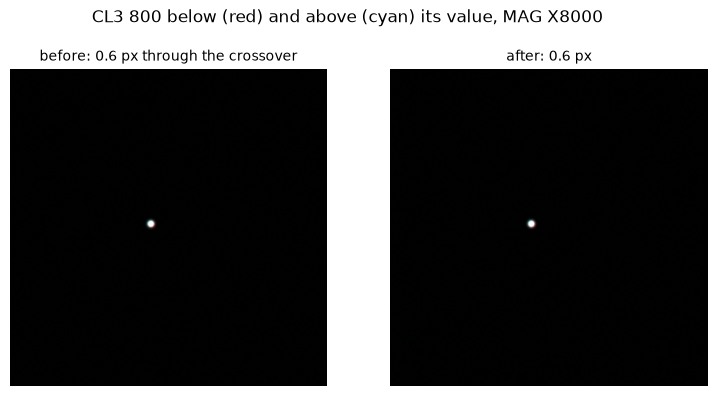

In [7]:
after = aperture_view()
results["aperture: beam moves through the crossover (px)"].append(beam_moves(after))
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
show(before, f"before: {beam_moves(before):.1f} px through the crossover", axes[0])
show(after, f"after: {beam_moves(after):.1f} px", axes[1])
fig.suptitle("CL3 800 below (red) and above (cyan) its value, MAG X8000")
plt.show()

After the script, the beam stays in place when CL3 takes it through the crossover. Example E21
asks for under 10 px. On this simulated NEOARM the beam hardly moves before the script either,
so the step has little to do here. The operator selects the large hole again for the steps
that follow.

In [8]:
scope.apertures[1]["size"] = 1  # the operator selects the 150 um hole

## Gun tilt and gun shift: no script yet

> **1 \- Gun Tilt**
> 
> * GOAL: Beam enters CL1 after the gun parallel to the optical axis
> * CONDITION:
>   * Spot size 1
>   * 50K Mag
>   * Centre the beam with BEAM SHIFT (CLA1)
> * METHOD:
>   * Wobble Anode ⇒ beam will oscillate in size and shift around the screen
>   * Adjust Gun Tilt X/Y (GUN2 X/Y)
> * ENDPOINT: beam oscillates in size around a fixed point

> **2 \- Gun Shift**
> 
> * GOAL: Beam enters CL1 after the gun on the optical axis
> * CONDITION:
>   * Spot size 5
>   * 25K initial Mag
>   * Converge beam to a point with Brightness / CL3
> * METHOD-ITERATE:
>   * Spot size 5
>   * Centre the beam with BEAM SHIFT (CLA1)
>     ————
>   * Spot size 1
>   * Centre the beam with GUN SHIFT (GUN1)
>     ————
>   * Increase Mag progressively until 200K
> * ENDPOINT: beam does not move much when changing spot size 1 ⇒ 5
> * OUTER-ITERATE: Repeat / Check **Gun Tilt Alignment**

jemwrap can set the gun tilt and shift (GunA1, GunA2). The simulated NEOARM has no gun. Its beam
starts at a point source on the axis. A script for these steps needs a gun in the simulator.

## Spot alignment, corrector beam tilt and condenser astigmatism: no script yet

> **Spot Alignment**
> No procedure for this???
> Only one deflector X/Y setting for this
> Does not change substantially between spot sizes, factory setting? How to check it is correct.
> NOTE: when changing spot size, CL1, CL3, SPOT ALIGN and COND STIG all change. CL3 value is some fixed value for each spot size plus a “hidden” offset for the current CL3 brightness setting.

> **Corrector Beam Tilt**
> If at this stage the beam intensity is heterogeneous (concentrated towards one direction while condensed), then it can be useful to adjust the beam tilt of the corrector.
> 
> * GOAL: Beam has a homogeneous angular intensity distribution (not necessarily radially)
> * CONDITION:
>   * Imaging mode
>   * 50K Mag, progressive
> * METHOD:
>   * Within ASCOR (corrector software) adjust **User Beam Tilt X/Y**
>   * Changing the Beam Tile setting will shift the beam on the screen ⇒ bring it back to the centre using **BEAM SHIFT (CLA1)**
> * ENDPOINT: beam angular intensity distribution uniform up to a high magnification / condenser setting

> **Condenser Astigmatism**
> 
> * GOAL: Beam is circular
> * CONDITION:
>   * 200K Mag
> * METHOD:
>   * Converge the beam with Brightness / CL3
>   * Adjust Condenser Stig X/Y to make the spot circular
>   * Check both sides of crossover (converge through BRIGHTNESS / CL3)

The guide has no procedure for the spot alignment. The simulated NEOARM starts with each spot's
SpotA set as after an operator's spot alignment. The operator sets the corrector beam tilt in
the corrector's own software, which jemwrap does not reach. The simulated NEOARM has no condenser
astigmatism. A script for the condenser stigmator needs hidden astigmatism in the simulator.

## Pivot points: tilt balance

> **1 \- Pivot Points: Tilt Balance:**
> 
> * GOAL: The beam can Tilt on the sample plane without Shifting
> * CONDITION:
>   * Imaging Mode
>   * Centre beam with BEAM SHIFT / CLA1
>   * Converged beam with Brightness / CL3
>   * Initial magnification appropriate to wobbling strength and current alignment (200K)
> * METHOD \- ITERATE:
>   * Activate Tilt X wobbler ⇒ the beam oscillates in X
>   * Adjust TILT BALANCE X to minimise the oscillation
>   * Deactivate Tilt X wobbler
>     ————
>   * Activate Tilt Y wobbler ⇒ the beam oscillates in Y
>   * Adjust TILT BALANCE Y to minimise the oscillation
>   * Deactivate Tilt Y wobbler
>     ————
>   * Increase Magnification and repeat
> * ENDPOINT: The wobbling beam is stationary in X / Y to a high magnification

`tilt_balance.py` works from X15k to X500k, row by row. At each row it centres the beam with
CLA1 and wobbles the beam tilt CLA2 along x and then y. It sets TILT BALANCE where the beam swings
least. The view wobbles CLA2 by 200 units at X30k.

In [9]:
def tilt_view():
    return two_frames(MAG, 12, {"CLA2": (200, 0)}, {"CLA2": (-200, 0)})


before = tilt_view()
results["tilt balance: Tilt X wobbler swings the beam (px)"] = [beam_moves(before)]

CL3 -> 31493 -> 33493
CL3 -> 31493 -> 33493
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


In [10]:
run("tilt_balance.py")

function mode -> MAG
selector -> 9
MAG row 9: 15000
CLA1 -> (11116, 32149) (trial)
CLA1 -> (11136, 32149) (trial)


CLA1 -> (11176, 32149) (trial)
CLA1 -> (11096, 32169) (trial)
CLA1 -> (11096, 32189) (trial)
CLA1 -> (11096, 32229) (trial)


CLA1 -> (10290, 31776)
TiltBal -> (25546, 25488) (probe)
TiltBal -> (25536, 25488)
CLA2 -> (38484, 44321)


CLA2 -> (38084, 44321)
CLA2 -> (38284, 44321)
tilt x wobble after the balance: swing [0. 0.] px
TiltBal -> (25536, 25498) (probe)
TiltBal -> (25536, 25488)
CLA2 -> (38284, 44521)
CLA2 -> (38284, 44121)


CLA2 -> (38284, 44321)
tilt y wobble after the balance: swing [ 0.1 -0. ] px
selector -> 10
MAG row 10: 20000
CLA1 -> (10310, 31776) (trial)


CLA1 -> (10330, 31776) (trial)
CLA1 -> (10290, 31796) (trial)
CLA1 -> (10290, 31816) (trial)
CLA1 -> (10682, 31886)
TiltBal -> (25546, 25488) (probe)


... (40 outputs left out)

CLA1 -> (11365, 32207) (trial)
CLA1 -> (11363, 32187)
TiltBal -> (25546, 25488) (probe)


TiltBal -> (25536, 25488)
CLA2 -> (38484, 44321)
CLA2 -> (38084, 44321)
CLA2 -> (38284, 44321)
tilt x wobble after the balance: swing [0.1 0.1] px
TiltBal -> (25536, 25498) (probe)
TiltBal -> (25536, 25488)
CLA2 -> (38284, 44521)


CLA2 -> (38284, 44121)
CLA2 -> (38284, 44321)
tilt y wobble after the balance: swing [ 0.2 -0.1] px
CLA2 -> (38484, 44321)
CLA2 -> (38084, 44321)
CLA2 -> (38284, 44321)
E10: tilt x wobbler at the last row swings the beam 0.1 px, under 10 px


CLA2 -> (38284, 44521)
CLA2 -> (38284, 44121)
CLA2 -> (38284, 44321)
E10: tilt y wobbler at the last row swings the beam 0.2 px, under 10 px
TiltBal now (25536, 25488)
every value but TiltBal -> its value at the start
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


CL3 -> 31493 -> 33493
CL3 -> 31493 -> 33493
eos.current_mag_selector_id -> 13, this mode's value at the start


deflectors.PLA -> (32768, 32768), this mode's value at the start


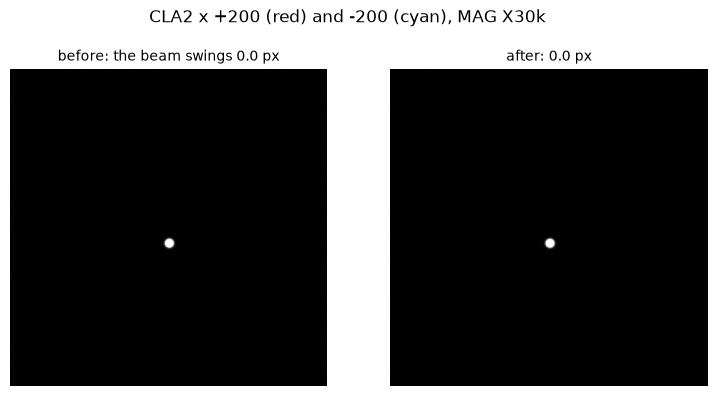

In [11]:
after = tilt_view()
results["tilt balance: Tilt X wobbler swings the beam (px)"].append(beam_moves(after))
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
show(before, f"before: the beam swings {beam_moves(before):.1f} px", axes[0])
show(after, f"after: {beam_moves(after):.1f} px", axes[1])
fig.suptitle("CLA2 x +200 (red) and -200 (cyan), MAG X30k")
plt.show()

After the script, the tilt wobbler does not move the beam on the specimen. Example E10 asks for
under 10 px. A balance whose wobble swings the beam less than half a pixel stays as it is. The
cell below shows how far the script moved TiltBal.

In [12]:
print(
    "TiltBal moved by",
    np.subtract(read_value(monitor, "deflectors.TiltBal"), scope_start["TiltBal"]),
)

TiltBal moved by [0 0]


## Pivot points: shift balance

> **2 \- Pivot Point: Shift Balance:**
> 
> * GOAL: The beam can shift on the sample plane without tilting.
> * CONDITION:
>   * Diffraction Mode
>   * Minimise diffraction spot with Brightness / CL3 (anti-clockwise)
>     * NOTE: Instructions say “Turn completely anti-clockwise CL3”, then use DIFF FOCUS. To-check ⇒ if really fully anti-clockwise?
>   * Converged diffraction spot caustic with DIFF FOCUS (IL1)
> * METHOD-ITERATE:
>   * Activate Shift X wobbler ⇒ the beam oscillates in X
>   * Adjust SHIFT BALANCE X to minimise the oscillation
>   * Deactivate Shift X wobbler
>     ————
>   * Activate Shift Y wobbler ⇒ the beam oscillates in Y
>   * Adjust SHIFT BALANCE Y to minimise the oscillation
>   * Deactivate Shift Y wobbler
>     ————
>   * Increase Camera Length and repeat
> * NOTE:
>   * If the oscillation is oval in shape, adjust ANGLE BALANCE X / Y to squash the oval into a line, then minimise with SHIFT BALANCE X / Y
> * ENDPOINT: The wobbling beam is stationary in X / Y to a high camera length
> * OUTER-ITERATE: Repeat / Check **Condenser Pivot Points Tilt**

`shift_balance.py` works in DIFF from 30 cm to 150 cm, row by row. At each row it keeps the
diffraction spot in the middle with the projector deflector PLA and wobbles the beam shift CLA1.
It sets SHIFT BALANCE where the spot swings least. A pure shift does not change the beam's angle,
so in DIFF the spot stands still. The view wobbles CLA1 by 30 units at 80 cm.

In [13]:
def shift_view():
    return two_frames(DIFF, 10, {"CLA1": (30, 0)}, {"CLA1": (-30, 0)})


before = shift_view()
results["shift balance: Shift X wobbler swings the spot (px)"] = [beam_moves(before)]

CL3 -> 31493 -> 33493


CL3 -> 31493 -> 33493
eos.current_mag_selector_id -> 0, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


In [14]:
run("shift_balance.py")

function mode -> DIFF
selector -> 6
DIFF row 6: camera length 30 cm
PLA -> (33768, 32768) (trial)


PLA -> (32768, 33768) (trial)


PLA -> (28380, 32918)


ShiftBal -> (28214, 28248) (probe)
ShiftBal -> (28204, 28248)
CLA1 -> (11103, 32149)
CLA1 -> (11089, 32149)


CLA1 -> (11096, 32149)
shift x wobble after the balance: swing [0.1 0.1] px
ShiftBal -> (28204, 28258) (probe)
ShiftBal -> (28204, 28248)
CLA1 -> (11096, 32156)


CLA1 -> (11096, 32142)


... (41 outputs left out)

PLA -> (13859, 28891) (trial)
PLA -> (12859, 29891) (trial)
PLA -> (12860, 28890)
CLA1 -> (11103, 32149)


CLA1 -> (11089, 32149)
CLA1 -> (11096, 32149)
shift x wobble after the balance: swing [ 0.  -0.1] px


ShiftBal -> (30172, 30258) (probe)
ShiftBal -> (30172, 30248)
CLA1 -> (11096, 32156)
CLA1 -> (11096, 32142)


CLA1 -> (11096, 32149)
shift y wobble after the balance: swing [ 0.1 -0.2] px
CLA1 -> (11103, 32149)
CLA1 -> (11089, 32149)
CLA1 -> (11096, 32149)
E10: shift x wobbler at the last row swings the spot 0.0 px, under 10 px
CLA1 -> (11096, 32156)
CLA1 -> (11096, 32142)
CLA1 -> (11096, 32149)
E10: shift y wobbler at the last row swings the spot 0.2 px, under 10 px
ShiftBal now (30172, 30248)
every value but ShiftBal -> its value at the start
eos.current_mag_selector_id -> 0, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


CL3 -> 31493 -> 33493
CL3 -> 31493 -> 33493
eos.current_mag_selector_id -> 0, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


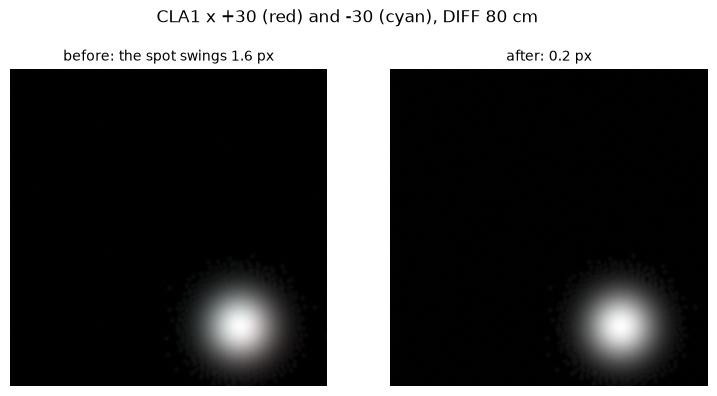

In [15]:
after = shift_view()
results["shift balance: Shift X wobbler swings the spot (px)"].append(beam_moves(after))
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
show(before, f"before: the spot swings {beam_moves(before):.1f} px", axes[0])
show(after, f"after: {beam_moves(after):.1f} px", axes[1])
fig.suptitle("CLA1 x +30 (red) and -30 (cyan), DIFF 80 cm")
plt.show()

The cell below shows how far the script moved ShiftBal. The hidden error is (-300, 200), and it
barely shows in this column. The script moves ShiftBal further, up to its largest step. The
swing that it nulls in DIFF also holds the error of the diffraction focus. The guide's own note
at the diff focus step names this coupling. A script for the diff focus would have to separate
the two first.

In [16]:
print(
    "ShiftBal moved by",
    np.subtract(read_value(monitor, "deflectors.ShiftBal"), scope_start["ShifBal"]),
)

ShiftBal moved by [1968 2000]


## Condenser alignment tilt (CLA2) with the HT wobbler: CLA2 takes away only part

> **Condenser Alignment Tilt (CLA2) \- HT Wobbler**
> 
> * GOAL: Beam is parallel to optical axis when entering OL
> * CONDITION:
>   * 500K Mag
>   * Characteristic feature of sample is imaged and at correct Z height
>   * STD FOCUS (Neutral OL-Fine)
> * METHOD:
>   * HT Wobbler ⇒ Beam and Features in image oscillate in position and size
>   * Adjust BEAM-TILT X / Y (CLA2) until Features in image oscillate in size but not position
>   * NOTE: Beam itself may continue to move even when correctly aligned, but the features should stay stationary

`ht_centre.py` works at X30k with the beam spread by CL3 over a cross grating in focus. With the
HT wobbler on, it measures how far the grating's features swing between frames
(cross-correlation). It moves CLA2 to where they swing least. It stops when a step of CLA2 lowers
the swing by less than 10 %, and it reports the swing left. The operator puts the grating in.

In [17]:
scope.specimen = CROSS_GRATING  # the operator puts the cross grating in, in focus


def ht_view():
    return two_frames(MAG, 12, {}, {}, cl3_step=3000, ht_wobbler=True)


def features_move(frames):
    """Return how far the specimen's features move from the first frame to the second, in px."""
    return float(np.hypot(*feature_shift(*frames)))


before = ht_view()
results["condenser tilt: features swing with the HT wobbler (px)"] = [features_move(before)]

CL3 -> 34493 -> 36493


CL3 -> 34493 -> 36493
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


In [18]:
try:
    run("ht_centre.py")
except RuntimeError as error:
    print(f"ht_centre.py stopped: {error}")

function mode -> MAG
selector -> 12
CL3 -> 34493 -> 36493
HT wobbler -> on
CLA2 -> (38284, 44321)


CLA2 -> (38784, 44321)


CLA2 -> (37784, 44321)


CLA2 -> (38284, 44821)


CLA2 -> (38284, 43821)


CLA2 -> (38784, 44821)


... (4 outputs left out)

CLA2 -> (38677, 44039)


CLA2 -> (39177, 45039)


CLA2 at (38677, 44539): the image swings 5.9 px
CLA2 -> (38284, 44321)


E24: CLA2 at its least swing; the HT wobbler still swings the image 5.9 px, which the beam tilt cannot take away (on the simulated NEOARM: CL1 and CL3 off the axis, for the gun and spot alignments)
every value but CLA2 -> its value at the start
CL3 -> 31493
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


CL3 -> 34493 -> 36493
CL3 -> 34493 -> 36493
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


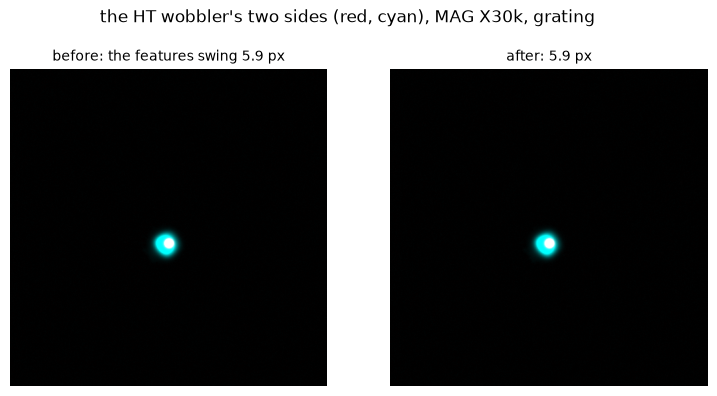

In [19]:
after = ht_view()
results["condenser tilt: features swing with the HT wobbler (px)"].append(features_move(after))
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
show(before, f"before: the features swing {features_move(before):.1f} px", axes[0])
show(after, f"after: {features_move(after):.1f} px", axes[1])
fig.suptitle("the HT wobbler's two sides (red, cyan), MAG X30k, grating")
plt.show()

**Why a swing stays.** After the tilt balance, CLA2 tilts the beam about a point on the
specimen, by about +-38 mrad over half its range. The rest of the swing does not come from a
tilt that CLA2 can take away. In the simulated NEOARM, CL1 and CL3 sit 2 to 3 um off the axis.
Their strength follows the high tension. So with the wobbler, the beam's tilt on the specimen
changes between the frames. A fixed tilt from CLA2 cannot cancel a tilt that changes. In a test
of 2026-11-22, with the corrector imaging, CL1 and CL3 on the axis lowered the swing from about
6 px to 1 px. With every lens and the SightX on the axis, the swing was 0.

In the guide this step comes after the gun and spot alignments. Those bring the beam through the
condenser on its axis, and they have no script yet (above). The swing here is at X30k with an HT
wobbler of +-100 V. That amplitude is a choice, since the NEOARM's is not known. At the guide's
X500k the same misalignment would swing the image about 17 times as far.

The operator takes the grating out again.

In [20]:
scope.specimen = None  # the operator takes the grating out

## Objective stigmator, diff focus and image focus: no script yet

> **Objective Stigmator**
> 
> * GOAL: Minimise Objective lens astigmatism
> * CONDITION:
>   * 500K+ Mag
>   * Amorphous region of the sample. What to do if no amorphous region is available?
>   * Imaging Mode
> * METHOD:
>   * Display FFT of the image
>   * Use OL-STIG X/Y to make the FFT rings circular

> **Diff focus**
> Unclear how this interacts with the alignment for shift pivot points, how to decouple them?
> 
> * GOAL: Diffraction plane is properly imaged by IL1 in diff mode
> * ENDPOINT: Transmitted beam in the diffraction pattern is stationary under real-space beam shift
> * CONDITION:
>   * 50K Mag
>   * Diffraction Mode
>   * Point-like diffraction spots (with CL3 / Brightness)
> * METHOD:
>   * Activate Shift Wobbler X/Y together (or activate NanoMegas scanning)
>   * Use DIFF FOCUS to minimise the movement of the transmitted beam

> **Image Focus (Sample height)**
> 
> * GOAL: Ensure that the sample plane is at the centre of the objective lens field (and therefore “in focus”.
> * CONDITION:
>   * MAG mode, appropriate magnification for features
>   * Above alignments completed / satisfactory
>   * Wide beam to cover most of screen, with features visible
> * METHOD:
>   * Adjust sample Z to minimise contrast in the image
>   * Activate Wobblers Image X / Image Y sequentially, remaining contrast should not move
> * ENDPOINT: Minimised contrast in image of sample

The simulated NEOARM has no objective astigmatism, so a stigmator script needs hidden
astigmatism first. Diff focus and the shift balance both null the movement of the transmitted
beam under a beam shift, as the guide's own note says. A script must first separate the two.
The guide's condition of point-like diffraction spots needs the smallest diffraction spot. The
routine `smallest_spot` finds it with CL3. Image focus moves the specimen with stage Z, which
PyJEM can set but not read.

## A second pass

The guide says that the whole set should likely be looped over more than once. The second pass
runs the same scripts on the aligned microscope. A step that is done changes little.

In [21]:
scope.apertures[1]["size"] = 4
run("centre_aperture.py")
results["aperture: beam moves through the crossover (px)"].append(beam_moves(aperture_view()))
scope.apertures[1]["size"] = 1
run("tilt_balance.py")
results["tilt balance: Tilt X wobbler swings the beam (px)"].append(beam_moves(tilt_view()))
run("shift_balance.py")
results["shift balance: Shift X wobbler swings the spot (px)"].append(beam_moves(shift_view()))
scope.specimen = CROSS_GRATING
try:
    run("ht_centre.py")
except RuntimeError as error:
    print(f"ht_centre.py stopped: {error}")
results["condenser tilt: features swing with the HT wobbler (px)"].append(features_move(ht_view()))
scope.specimen = None

function mode -> MAG
selector -> 6
CL3 -> 31493 -> 33493
CLA1 -> (11116, 32149) (trial)
CLA1 -> (11136, 32149) (trial)
CLA1 -> (11176, 32149) (trial)
CLA1 -> (11256, 32149) (trial)
CLA1 -> (11096, 32169) (trial)
CLA1 -> (11096, 32189) (trial)


CLA1 -> (11096, 32229) (trial)
CLA1 -> (11096, 32309) (trial)
CLA1 -> (10051, 31585)
aperture selected: 0
CL3 -> 30693 -> 32693
CL3 -> 32293 -> 34293
CL3 -> 31493 -> 33493
aperture at (2048, 2048): the beam moves [-0.4 -0.4] px through the crossover
CL3 -> 30693 -> 32693
CL3 -> 32293 -> 34293
CL3 -> 31493 -> 33493
E21: the beam moves 0.5 px through the crossover, under 10 px
aperture now (2048, 2048)
every value but the aperture position -> its value at the start
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


CL3 -> 30693 -> 32693
CL3 -> 32293 -> 34293
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start
function mode -> MAG
selector -> 9
MAG row 9: 15000
CLA1 -> (11116, 32149) (trial)
CLA1 -> (11136, 32149) (trial)


CLA1 -> (11176, 32149) (trial)
CLA1 -> (11096, 32169) (trial)
CLA1 -> (11096, 32189) (trial)
CLA1 -> (11096, 32229) (trial)
CLA1 -> (10257, 31760)
TiltBal -> (25546, 25488) (probe)
TiltBal -> (25536, 25488)
CLA2 -> (38484, 44321)


CLA2 -> (38084, 44321)
CLA2 -> (38284, 44321)
tilt x wobble after the balance: swing [0. 0.] px
TiltBal -> (25536, 25498) (probe)
TiltBal -> (25536, 25488)
CLA2 -> (38284, 44521)
CLA2 -> (38284, 44121)
CLA2 -> (38284, 44321)
tilt y wobble after the balance: swing [ 0. -0.] px
selector -> 10
MAG row 10: 20000
CLA1 -> (10277, 31760) (trial)
CLA1 -> (10297, 31760) (trial)


CLA1 -> (10257, 31780) (trial)
CLA1 -> (10257, 31800) (trial)
CLA1 -> (10661, 31872)
TiltBal -> (25546, 25488) (probe)
TiltBal -> (25536, 25488)
CLA2 -> (38484, 44321)
CLA2 -> (38084, 44321)
CLA2 -> (38284, 44321)
tilt x wobble after the balance: swing [0. 0.] px
TiltBal -> (25536, 25498) (probe)


... (46 outputs left out)

CLA2 -> (38784, 44321)


CLA2 -> (39284, 45321)


CLA2 at (38784, 44821): the image swings 5.8 px
CLA2 -> (38284, 44321)


E24: CLA2 at its least swing; the HT wobbler still swings the image 5.9 px, which the beam tilt cannot take away (on the simulated NEOARM: CL1 and CL3 off the axis, for the gun and spot alignments)
every value but CLA2 -> its value at the start
CL3 -> 31493
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start
CL3 -> 34493 -> 36493
CL3 -> 34493 -> 36493
eos.current_mag_selector_id -> 13, this mode's value at the start
deflectors.PLA -> (32768, 32768), this mode's value at the start


## The end points

Each row is the end point of one step. Its columns are before the first pass, after it, and
after the second pass.

In [22]:
print(f"{'end point':55s} {'before':>8s} {'pass 1':>8s} {'pass 2':>8s}")
for name, values in results.items():
    shown = "".join(f"{v:8.1f} " for v in values)
    print(f"{name:55s} {shown}")

end point                                                 before   pass 1   pass 2
aperture: beam moves through the crossover (px)              0.6      0.6      0.6 
tilt balance: Tilt X wobbler swings the beam (px)            0.0      0.0      0.0 
shift balance: Shift X wobbler swings the spot (px)          1.6      0.2      0.2 
condenser tilt: features swing with the HT wobbler (px)      5.9      5.9      5.9 
